In [2]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = r"C:\Users\LAKSHMI DEVI\Downloads\archive\covid_19_clean_complete.csv"

df = pd.read_csv(file_path)

print(df.head())

  Province/State Country/Region       Lat       Long        Date  Confirmed  \
0            NaN    Afghanistan  33.93911  67.709953  2020-01-22          0   
1            NaN        Albania  41.15330  20.168300  2020-01-22          0   
2            NaN        Algeria  28.03390   1.659600  2020-01-22          0   
3            NaN        Andorra  42.50630   1.521800  2020-01-22          0   
4            NaN         Angola -11.20270  17.873900  2020-01-22          0   

   Deaths  Recovered  Active             WHO Region  
0       0          0       0  Eastern Mediterranean  
1       0          0       0                 Europe  
2       0          0       0                 Africa  
3       0          0       0                 Europe  
4       0          0       0                 Africa  


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
print(df.info())

Dataset Shape: (49068, 10)

Column Names:
Index(['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed',
       'Deaths', 'Recovered', 'Active', 'WHO Region'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  str    
 1   Country/Region  49068 non-null  str    
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  str    
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  str    
dtypes: float64(2), int64(4), str(4)
memory usage: 3.7 MB
None


In [4]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Province/State    34404
Country/Region        0
Lat                   0
Long                  0
Date                  0
Confirmed             0
Deaths                0
Recovered             0
Active                0
WHO Region            0
dtype: int64


In [5]:
df["Province/State"] = df["Province/State"].fillna("Unknown")

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Province/State    0
Country/Region    0
Lat               0
Long              0
Date              0
Confirmed         0
Deaths            0
Recovered         0
Active            0
WHO Region        0
dtype: int64


In [6]:
df["Date"] = pd.to_datetime(df["Date"])

print("Date column converted successfully.")
print(df["Date"].head())

Date column converted successfully.
0   2020-01-22
1   2020-01-22
2   2020-01-22
3   2020-01-22
4   2020-01-22
Name: Date, dtype: datetime64[us]


In [7]:
print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate rows after cleaning:", df.duplicated().sum())

Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0


In [8]:
print("Statistical Summary:")
print(df[["Confirmed", "Deaths", "Recovered", "Active"]].describe())

Statistical Summary:
          Confirmed         Deaths     Recovered        Active
count  4.906800e+04   49068.000000  4.906800e+04  4.906800e+04
mean   1.688490e+04     884.179160  7.915713e+03  8.085012e+03
std    1.273002e+05    6313.584411  5.480092e+04  7.625890e+04
min    0.000000e+00       0.000000  0.000000e+00 -1.400000e+01
25%    4.000000e+00       0.000000  0.000000e+00  0.000000e+00
50%    1.680000e+02       2.000000  2.900000e+01  2.600000e+01
75%    1.518250e+03      30.000000  6.660000e+02  6.060000e+02
max    4.290259e+06  148011.000000  1.846641e+06  2.816444e+06


In [10]:
country_cases = df.groupby("Country/Region")["Confirmed"].max().sort_values(ascending=False)

print("Top 10 Countries by Confirmed Cases:")
print(country_cases.head(10))

Top 10 Countries by Confirmed Cases:
Country/Region
US                4290259
Brazil            2442375
India             1480073
Russia             816680
South Africa       452529
Mexico             395489
Peru               389717
Chile              347923
United Kingdom     300111
Iran               293606
Name: Confirmed, dtype: int64


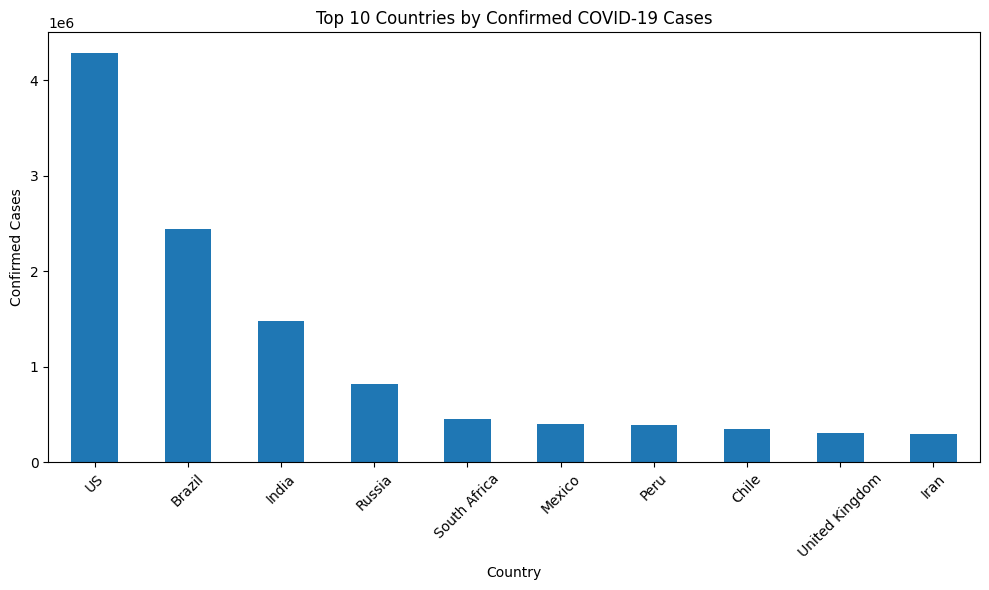

In [12]:
top_10 = country_cases.head(10)

plt.figure(figsize=(10, 6))

top_10.plot(kind="bar")

plt.title("Top 10 Countries by Confirmed COVID-19 Cases")
plt.xlabel("Country")
plt.ylabel("Confirmed Cases")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

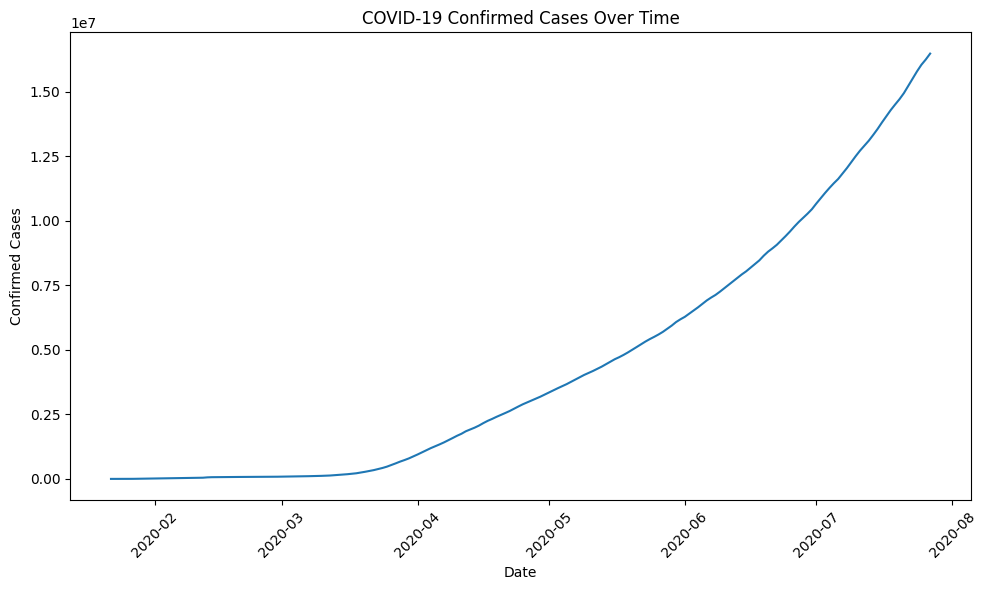

In [13]:
daily_confirmed = df.groupby("Date")["Confirmed"].sum()

plt.figure(figsize=(10, 6))

plt.plot(daily_confirmed.index, daily_confirmed.values)

plt.title("COVID-19 Confirmed Cases Over Time")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

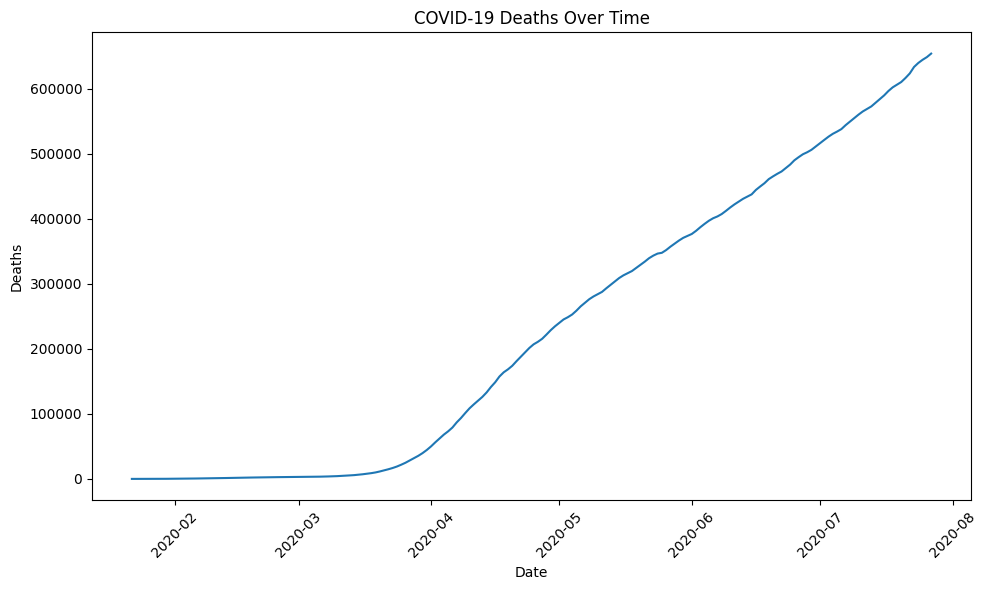

In [14]:
daily_deaths = df.groupby("Date")["Deaths"].sum()

plt.figure(figsize=(10, 6))

plt.plot(daily_deaths.index, daily_deaths.values)

plt.title("COVID-19 Deaths Over Time")
plt.xlabel("Date")
plt.ylabel("Deaths")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

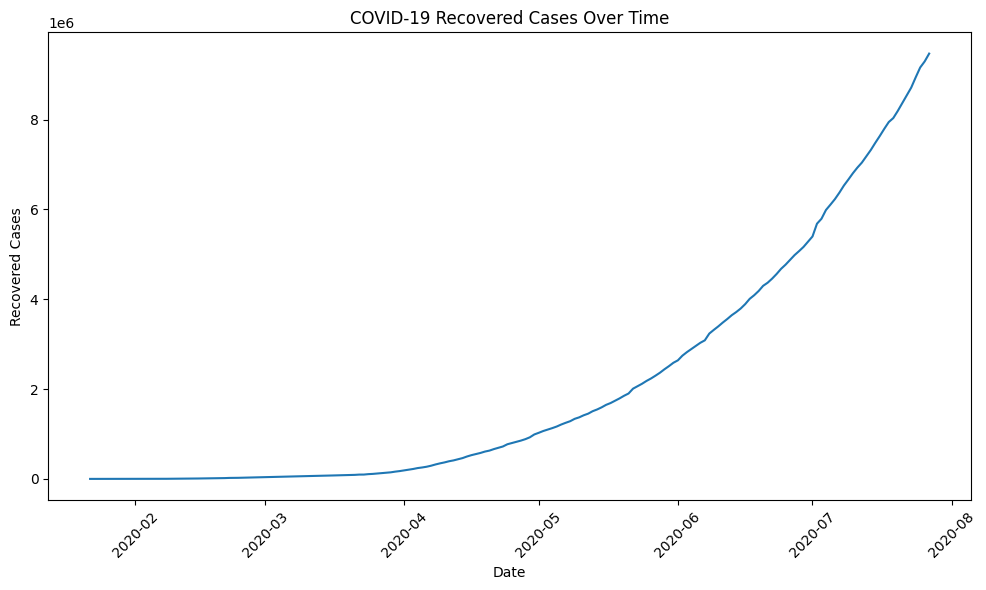

In [15]:
daily_recovered = df.groupby("Date")["Recovered"].sum()

plt.figure(figsize=(10, 6))

plt.plot(daily_recovered.index, daily_recovered.values)

plt.title("COVID-19 Recovered Cases Over Time")
plt.xlabel("Date")
plt.ylabel("Recovered Cases")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

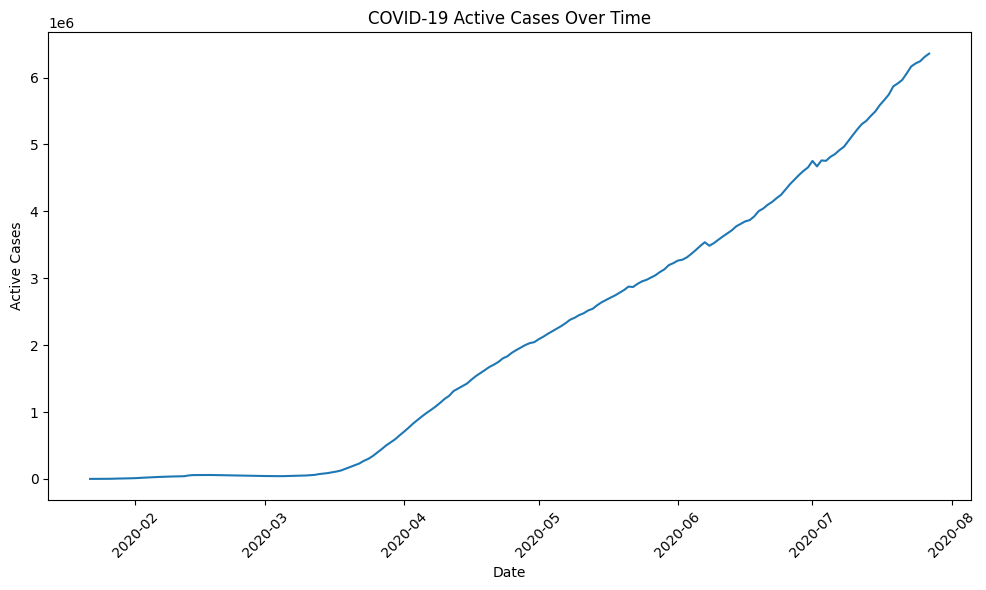

In [16]:
daily_active = df.groupby("Date")["Active"].sum()

plt.figure(figsize=(10, 6))

plt.plot(daily_active.index, daily_active.values)

plt.title("COVID-19 Active Cases Over Time")
plt.xlabel("Date")
plt.ylabel("Active Cases")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [17]:
print("======================================")
print("   COVID-19 DATA ANALYSIS COMPLETE")
print("======================================")

print("Total Records:", len(df))
print("Total Countries:", df["Country/Region"].nunique())
print("Date Range:", df["Date"].min(), "to", df["Date"].max())

print("\nFinal Missing Values:")
print(df.isnull().sum())

print("\nFinal Dataset Shape:", df.shape)

   COVID-19 DATA ANALYSIS COMPLETE
Total Records: 49068
Total Countries: 187
Date Range: 2020-01-22 00:00:00 to 2020-07-27 00:00:00

Final Missing Values:
Province/State    0
Country/Region    0
Lat               0
Long              0
Date              0
Confirmed         0
Deaths            0
Recovered         0
Active            0
WHO Region        0
dtype: int64

Final Dataset Shape: (49068, 10)


In [18]:
cleaned_file = r"C:\Users\LAKSHMI DEVI\Downloads\archive\covid_19_cleaned.csv"

df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")
print(cleaned_file)

Cleaned dataset saved successfully!
C:\Users\LAKSHMI DEVI\Downloads\archive\covid_19_cleaned.csv
